# DBA5101 Group Project 3
## Multi-Armed Bandits

AY2026/2027 Semester 1

**Deadline: Sunday, 15 November 2026, 23:59 (Singapore time).**

Read the project handout before starting. This notebook demonstrates the interface; you must design and implement your own arm-selection method.

Put `server_pull.py` in the same folder as this notebook. Use a Python 3.9+ kernel. The helper needs no third-party Python packages.

There are 24 arms, numbered **0 to 23**. Each successful call serves 100 visitors. The group budget is at most 1,000,000 pulls across all sessions, including test calls.

In [1]:
from getpass import getpass
from server_pull import configure, pull, status, UncertainPullError
# from server_pull_mock import configure, pull, status, UncertainPullError

ARMS = tuple(range(24))
VISITORS_PER_PULL = 100
MAX_GROUP_PULLS = 1_000_000

# Verified GP3 cloud server.
SERVER_URL = "https://gp3-bandit-2026.onrender.com"
configure(SERVER_URL)  # Configure once; this makes no network request.


## 1. Read an example response offline

The following values are illustrative. This cell makes no server request and uses no pulls. `Reward` is the sign-ups in one batch; `NetReward` and `Pull` describe the group account. Keep your own call log as well as the server counter.

In [2]:
example = {'Arm': '2', 'NetReward': 455, 'Pull': 30, 'Reward': 22}
print(example)
print(f"Batch conversion rate: {example['Reward'] / VISITORS_PER_PULL:.1%}")


{'Arm': '2', 'NetReward': 455, 'Pull': 30, 'Reward': 22}
Batch conversion rate: 22.0%


## 2. Make one live pull when ready

The public HTTPS server address is already filled in. A normal internet connection is sufficient; NUS Wi-Fi or VPN is not required. Use the experiment account assigned to your group, not your NUS login. Keep `RUN_LIVE = False` until you intend to use one pull. The setup cell calls `configure` once without making a network request. After a successful response, running the live cell again makes a new pull. If a response is uncertain, repeating the live cell with the same account and arm reuses the pending request. Do not rerun the setup cell while that request is unresolved.

The password is entered privately and is not saved in this file. Do not print it, paste it into code, or include it in your submission. Use one sequential experiment driver for the group. Allow at least 0.25 seconds between calls. The limit of five requests per second is shared by all group members. The full one-million-pull budget is shared across sessions, including test calls. New pulls close at the project deadline.


In [3]:
RUN_LIVE = False

if RUN_LIVE:
    username = input('Group username: ').strip()
    password = getpass('Group password: ')
    try:
        result = pull(username, password, 2)
        print(result)
        print(f"Batch conversion rate: {result['Reward'] / VISITORS_PER_PULL:.1%}")
    except UncertainPullError as error:
        print(error)
        print('Save the recovery fields above before restarting the kernel.')
    finally:
        del password
else:
    print('Offline mode. No request has been sent.')

Offline mode. No request has been sent.


The server uses a zero-based `Pull`: `Pull = 0` is the first completed pull. `status(username, password)` reports the number of pulls used without consuming a pull.

After an uncertain response, do not choose a new arm. If requests were rate-limited, wait at least one second before retrying. Retry the same arm with the same `request_id` and `expected_pull` shown in the error. For example, call `pull(username, password, 2, request_id=saved_request_id, expected_pull=saved_expected_pull)`. This retrieves the original result if it already completed. If it did not complete, it makes that one intended pull. Store the recovery fields privately with your experiment log; they are not the group password.

The helper remembers an uncertain request during the same Python session, so directly repeating `pull` with the same arm also reuses it. Do not run `configure` again while a request is pending. A kernel restart does not reset the group account. After restarting, configure the same server and use the saved recovery fields before requesting anything new. The helper does not make automatic retries.

If the server reports that another member has used the same counter, coordinate with your group, call `status`, and then decide whether to make a new pull. Contact Kerun Xu (e1521287@u.nus.edu) or Abilasha Swaminathan (abilasha@u.nus.edu) if access is unavailable.

## 3. Implement and analyse your method

Add your own code and explanations below. Useful items to record include the arm chosen, batch reward, cumulative sign-ups, and server pull counter for every request. Explain your method, why you selected it, and what the results support.

Avoid starting with a large automated run. Check the behaviour of your code first, then account for the pulls already used by all group members. Save results as you work so that analysis does not require repeating live requests.

In [4]:
import json
import logging
from logging import Logger
import math
import matplotlib.pyplot as plt
import os
import random
import shutil
import time

In [5]:
SEED = 42
random.seed(SEED)

### Helpers

In [6]:
def pull_arm(username: str, password: str, arm: int, logger: Logger) -> dict:
    result = pull(username, password, arm)
    logger.info(
        f'Pull Number: {result["Pull"] + 1} '
        + f'| Arm: {result["Arm"]} '
        + f'| Reward: {result["Reward"]} '
        + f'| Net Reward: {result["NetReward"]}'
    )
    return result


def update_arm_records(arm_records: dict, result: dict):
    arm = int(result["Arm"])
    reward = result["Reward"]

    arm_records[arm]["num_pulls"] += 1
    arm_records[arm]["total_reward"] += reward


def calculate_mean_rewards(arm_records: dict):
    arms_to_mean_rewards = dict()

    for arm, stats in arm_records.items():
        if stats["num_pulls"] == 0:
            mean_reward_for_arm = 0
        else:
            mean_reward_for_arm = stats["total_reward"] / stats["num_pulls"]

        arms_to_mean_rewards[arm] = mean_reward_for_arm

    return arms_to_mean_rewards


def select_best_arm_by_mean_reward(arm_records: dict, logger: Logger):
    arms_to_mean_rewards = calculate_mean_rewards(arm_records)

    best_arm, best_mean_reward = None, float("-inf")
    for arm, mean_reward in arms_to_mean_rewards.items():
        if mean_reward > best_mean_reward:
            best_arm = arm
            best_mean_reward = mean_reward

    logger.info(
        f"Chose the best arm so far (by mean reward): {best_arm} "
        + f"| Mean reward of chosen arm: {best_mean_reward}"
    )

    return best_arm


def select_random_arm(arms: list[int], logger: Logger):
    arm = random.choice(arms)

    logger.info(f"Chose a random arm: {arm}")

    return arm


def save_arm_records(arm_records: dict, file_path: str):
    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(arm_records, f, indent=4)


def load_arm_records(file_path: str):
    with open(file_path, "r", encoding="utf-8") as f:
        saved = json.load(f)

    return {
        int(arm): {
            "num_pulls": int(stats["num_pulls"]),
            "total_reward": int(stats["total_reward"]),
        }
        for arm, stats in saved.items()
    }


def save_cumulative_rewards(cumulative_rewards: list[int], file_path: str):
    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(cumulative_rewards, f)


def load_cumulative_rewards(file_path: str):
    with open(file_path, "r", encoding="utf-8") as f:
        return json.load(f)


def pull_arm_and_process_result(
    username: str,
    password: str,
    arm: int,
    arm_records: dict,
    cumulative_rewards: list[int],
    results_file_path: str,
    cumulative_rewards_file_path: str,
    logger: Logger,
    checkpoint_interval: int = 1000
):
    try:
        # Allow some time between calls
        time.sleep(0.25)

        result = pull_arm(username, password, arm, logger)
        update_arm_records(arm_records, result)

        previous_cumulative_reward = cumulative_rewards[-1] if cumulative_rewards else 0
        cumulative_rewards.append(previous_cumulative_reward + int(result["Reward"]))

        num_completed = get_num_pulls_completed(arm_records)
        if num_completed % checkpoint_interval == 0:
            save_arm_records(arm_records, results_file_path)
            save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)

        return True
        
    except Exception as error:
        logger.error(error)
        logger.error("Terminating. Save the recovery fields (if any) before restarting the kernel")
        save_arm_records(arm_records, results_file_path)
        save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
        return False


def get_num_pulls_completed(arm_records: dict):
    return sum(stats["num_pulls"] for stats in arm_records.values())

### Algorithm Functions

In [7]:
def conduct_explore_first(
    username: str,
    password: str,
    arms: list[int],
    num_pulls: int,
    num_exploration_per_arm: int,
    is_exploration_needed: bool = True
):
    logging_file_path = os.path.join("..", "logs", "explore_first.log")
    results_file_path = os.path.join("..", "results", "explore_first.json")
    cumulative_rewards_file_path = os.path.join(
        "..", "cumulative_rewards", "explore_first.json"
    )

    # Set up logger
    logger = logging.getLogger("explore_first")
    logger.setLevel(logging.INFO)
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(logging_file_path)
    handler.setFormatter(logging.Formatter("%(asctime)s - %(levelname)s - %(message)s"))
    logger.addHandler(handler)

    # Load existing records if any
    if os.path.isfile(results_file_path):
        arm_records = load_arm_records(results_file_path)
    else:
        arm_records = {
            arm: {"num_pulls": 0, "total_reward": 0}
            for arm in arms
        }

    if os.path.isfile(cumulative_rewards_file_path):
        cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)
    else:
        cumulative_rewards = list()

    if len(cumulative_rewards) != get_num_pulls_completed(arm_records):
        print(len(cumulative_rewards))
        print(get_num_pulls_completed(arm_records))
        raise ValueError(
            "Cumulative reward history and arm records do not match."
        )

    # Conduct exploration
    if is_exploration_needed:
        for arm in arms:
            for count in range(num_exploration_per_arm):
                logger.info(f"Beginning exploration {count + 1} for arm {arm}")

                is_pull_successful = pull_arm_and_process_result(
                    username,
                    password,
                    arm,
                    arm_records,
                    cumulative_rewards,
                    results_file_path,
                    cumulative_rewards_file_path,
                    logger
                )

                if not is_pull_successful:
                    return

    # Select best arm
    best_arm = select_best_arm_by_mean_reward(arm_records, logger)

    # Conduct exploitation
    num_pulls_completed = get_num_pulls_completed(arm_records)
    for pull_num in range(num_pulls_completed + 1, num_pulls + 1):
        logger.info(f"Beginning exploitation: pull {pull_num} / {num_pulls}")

        is_pull_successful = pull_arm_and_process_result(
            username,
            password,
            best_arm,
            arm_records,
            cumulative_rewards,
            results_file_path,
            cumulative_rewards_file_path,
            logger
        )

        if not is_pull_successful:
            return

    save_arm_records(arm_records, results_file_path)
    save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
    logger.info("Completed all pulls successfully")

    return arm_records

In [8]:
def conduct_ep_greedy(
    username: str,
    password: str,
    arms: list[int],
    num_pulls: int,
    epsilon: float
):
    epsilon_str_formatted = str(epsilon).replace(".", "_")
    logging_file_path = os.path.join("..", "logs", f"ep_greedy_{epsilon_str_formatted}.log")
    results_file_path = os.path.join("..", "results", f"ep_greedy_{epsilon_str_formatted}.json")
    cumulative_rewards_file_path = os.path.join(
        "..", "cumulative_rewards", f"ep_greedy_{epsilon_str_formatted}.json"
    )

    # Set up logger
    logger = logging.getLogger(f"ep_greedy_{epsilon_str_formatted}")
    logger.setLevel(logging.INFO)
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(logging_file_path)
    handler.setFormatter(logging.Formatter("%(asctime)s - %(levelname)s - %(message)s"))
    logger.addHandler(handler)

    # Load existing records if any
    if os.path.isfile(results_file_path):
        arm_records = load_arm_records(results_file_path)
    else:
        arm_records = {
            arm: {"num_pulls": 0, "total_reward": 0}
            for arm in arms
        }

    if os.path.isfile(cumulative_rewards_file_path):
        cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)
    else:
        cumulative_rewards = list()

    num_pulls_completed = get_num_pulls_completed(arm_records)
    if len(cumulative_rewards) != num_pulls_completed:
        raise ValueError(
            "Cumulative reward history and arm records do not match."
        )
    
    for pull_num in range(num_pulls_completed + 1, num_pulls + 1):
        logger.info(f"Beginning iteration {pull_num} / {num_pulls}")

        is_exploration = random.random() < epsilon
        if pull_num == 1 or is_exploration:  # Select random arm if this is the first pull (empty arm records)
            arm_to_pull = select_random_arm(arms, logger)
        else:
            arm_to_pull = select_best_arm_by_mean_reward(arm_records, logger)

        # Pull the selected arm
        is_pull_successful = pull_arm_and_process_result(
            username,
            password,
            arm_to_pull,
            arm_records,
            cumulative_rewards,
            results_file_path,
            cumulative_rewards_file_path,
            logger
        )

        if not is_pull_successful:
            return

    save_arm_records(arm_records, results_file_path)
    save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
    logger.info("Completed all pulls successfully")

    return arm_records

In [9]:
def conduct_adaptive_ep_greedy(
    username: str,
    password: str,
    arms: list[int],
    num_pulls: int,
    epsilon: float,
    alpha: float
):
    epsilon_str_formatted = str(epsilon).replace(".", "_")
    logging_file_path = os.path.join("..", "logs", f"adaptive_ep_greedy_{epsilon_str_formatted}.log")
    results_file_path = os.path.join("..", "results", f"adaptive_ep_greedy_{epsilon_str_formatted}.json")
    cumulative_rewards_file_path = os.path.join(
        "..", "cumulative_rewards", f"adaptive_ep_greedy_{epsilon_str_formatted}.json"
    )

    # Set up logger
    logger = logging.getLogger(f"adaptive_ep_greedy_{epsilon_str_formatted}")
    logger.setLevel(logging.INFO)
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(logging_file_path)
    handler.setFormatter(logging.Formatter("%(asctime)s - %(levelname)s - %(message)s"))
    logger.addHandler(handler)

    # Load existing records if any
    if os.path.isfile(results_file_path):
        arm_records = load_arm_records(results_file_path)
    else:
        arm_records = {
            arm: {"num_pulls": 0, "total_reward": 0}
            for arm in arms
        }

    if os.path.isfile(cumulative_rewards_file_path):
        cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)
    else:
        cumulative_rewards = list()

    num_pulls_completed = get_num_pulls_completed(arm_records)
    if len(cumulative_rewards) != num_pulls_completed:
        raise ValueError(
            "Cumulative reward history and arm records do not match."
        )
    
    for pull_num in range(num_pulls_completed + 1, num_pulls + 1):
        logger.info(f"Beginning iteration {pull_num} / {num_pulls}")

        decayed_epsilon = epsilon * math.exp(-alpha * (pull_num - 1))
        logger.info(f"Epsilon used: {decayed_epsilon}")

        is_exploration = random.random() < decayed_epsilon
        if pull_num == 1 or is_exploration:  # Select random arm if this is the first pull (empty arm records)
            arm_to_pull = select_random_arm(arms, logger)
        else:
            arm_to_pull = select_best_arm_by_mean_reward(arm_records, logger)

        # Pull the selected arm
        is_pull_successful = pull_arm_and_process_result(
            username,
            password,
            arm_to_pull,
            arm_records,
            cumulative_rewards,
            results_file_path,
            cumulative_rewards_file_path,
            logger
        )

        if not is_pull_successful:
            return

    save_arm_records(arm_records, results_file_path)
    save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
    logger.info("Completed all pulls successfully")

    return arm_records

In [10]:
def select_best_arm_by_ucb(arm_records: dict, iteration_num: int, logger: Logger):
    best_arm, best_ucb = None, float("-inf")
    for arm, stats in arm_records.items():
        count = stats["num_pulls"]

        # Calculate UCB score
        if count == 0:
            ucb = 0
        else:
            # To determine UCB score, we must normalise the reward to [0, 1]
            max_reward = VISITORS_PER_PULL
            normalised_reward = stats["total_reward"] / max_reward
            mean = normalised_reward / count
            ucb = mean + math.sqrt(2 * math.log(iteration_num) / count)

        if ucb > best_ucb:
            best_arm = arm
            best_ucb = ucb

    logger.info(f"Chose the best arm so far (by UCB): {best_arm} | UCB of chosen arm: {best_ucb}")

    return best_arm


def conduct_ucb1(
    username: str,
    password: str,
    arms: list[int],
    num_pulls: int,
    is_initialisation_needed: bool = True
):
    logging_file_path = os.path.join("..", "logs", "ucb1.log")
    results_file_path = os.path.join("..", "results", "ucb1.json")
    cumulative_rewards_file_path = os.path.join(
        "..", "cumulative_rewards", "ucb1.json"
    )

    # Set up logger
    logger = logging.getLogger("ucb1")
    logger.setLevel(logging.INFO)
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(logging_file_path)
    handler.setFormatter(logging.Formatter("%(asctime)s - %(levelname)s - %(message)s"))
    logger.addHandler(handler)

    # Load existing records if any
    if os.path.isfile(results_file_path):
        arm_records = load_arm_records(results_file_path)
    else:
        arm_records = {
            arm: {"num_pulls": 0, "total_reward": 0}
            for arm in arms
        }

    if os.path.isfile(cumulative_rewards_file_path):
        cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)
    else:
        cumulative_rewards = list()

    if len(cumulative_rewards) != get_num_pulls_completed(arm_records):
        raise ValueError(
            "Cumulative reward history and arm records do not match."
        )

    # Conduct initialisation
    if is_initialisation_needed:
        for arm in arms:
            logger.info(f"Beginning initialisation for arm {arm}")

            is_pull_successful = pull_arm_and_process_result(
                username,
                password,
                arm,
                arm_records,
                cumulative_rewards,
                results_file_path,
                cumulative_rewards_file_path,
                logger
            )

            if not is_pull_successful:
                return
        
    num_pulls_completed = get_num_pulls_completed(arm_records)
    for pull_num in range(num_pulls_completed + 1, num_pulls + 1):
        logger.info(f"Beginning iteration {pull_num} / {num_pulls}")

        # Select best arm
        best_arm = select_best_arm_by_ucb(arm_records, pull_num, logger)

        is_pull_successful = pull_arm_and_process_result(
            username,
            password,
            best_arm,
            arm_records,
            cumulative_rewards,
            results_file_path,
            cumulative_rewards_file_path,
            logger
        )

        if not is_pull_successful:
            return

    save_arm_records(arm_records, results_file_path)
    save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
    logger.info("Completed all pulls successfully")

    return arm_records

In [11]:
def select_arm_by_thompson_sampling(arm_records: dict, arms: list[int], logger: Logger):
    sampled_rates = dict()

    for arm in arms:
        stats = arm_records[arm]
        successes = stats["total_reward"]
        failures = VISITORS_PER_PULL * stats["num_pulls"] - successes

        sampled_rates[arm] = random.betavariate(1 + successes, 1 + failures)

    chosen_arm = max(sampled_rates, key=sampled_rates.get)

    logger.info(
        f"Chose an arm by Thompson sampling: {chosen_arm} "
        f"| Sampled rate: {sampled_rates[chosen_arm]}"
    )

    return chosen_arm


def conduct_thompson_sampling(
    username: str,
    password: str,
    arms: list[int],
    num_pulls: int
):
    logging_file_path = os.path.join("..", "logs", "thompson_sampling.log")
    results_file_path = os.path.join("..", "results", "thompson_sampling.json")
    cumulative_rewards_file_path = os.path.join(
        "..", "cumulative_rewards", "thompson_sampling.json"
    )

    # Set up logger
    logger = logging.getLogger("thompson_sampling")
    logger.setLevel(logging.INFO)
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(logging_file_path)
    handler.setFormatter(logging.Formatter("%(asctime)s - %(levelname)s - %(message)s"))
    logger.addHandler(handler)

    # Load existing records if any
    if os.path.isfile(results_file_path):
        arm_records = load_arm_records(results_file_path)
    else:
        arm_records = {
            arm: {"num_pulls": 0, "total_reward": 0}
            for arm in arms
        }

    if os.path.isfile(cumulative_rewards_file_path):
        cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)
    else:
        cumulative_rewards = list()

    num_pulls_completed = get_num_pulls_completed(arm_records)
    if len(cumulative_rewards) != num_pulls_completed:
        raise ValueError(
            "Cumulative reward history and arm records do not match."
        )

    for pull_num in range(num_pulls_completed + 1, num_pulls + 1):
        logger.info(f"Beginning iteration {pull_num} / {num_pulls}")

        arm_to_pull = select_arm_by_thompson_sampling(
            arm_records, arms, logger
        )

        is_pull_successful = pull_arm_and_process_result(
            username,
            password,
            arm_to_pull,
            arm_records,
            cumulative_rewards,
            results_file_path,
            cumulative_rewards_file_path,
            logger
        )

        if not is_pull_successful:
            return

    save_arm_records(arm_records, results_file_path)
    save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)
    logger.info("Completed all pulls successfully")

    return arm_records

### Experimentation

In [12]:
def calculate_average_reward_per_pull(arm_records: dict):
    total_pulls = get_num_pulls_completed(arm_records)
    total_reward = sum(
        stats["total_reward"] for stats in arm_records.values()
    )

    if total_pulls == 0:
        return 0
    
    return total_reward / total_pulls

In [13]:
NUM_PULLS_PER_ALGORITHM = 10000

# Explore first
NUM_EXPLORATION_PER_ARM = 100

# Adaptive epsilon greedy
ALPHA_DECAY = 0.0003

In [14]:
# folders = [
#     os.path.join("..", "logs"),
#     os.path.join("..", "results"),
#     os.path.join("..", "cumulative_rewards"),
#     os.path.join("..", "plots"),
# ]

# for folder in folders:
#     if os.path.exists(folder):
#         shutil.rmtree(folder)
#     os.makedirs(folder)

In [ ]:
# status("username", "password")

In [16]:
# import re

# log_file_path = os.path.join("..", "logs", "adaptive_ep_greedy_0_1.log")
# results_file_path = os.path.join("..", "results", "adaptive_ep_greedy_0_1.json")
# cumulative_rewards_file_path = os.path.join(
#     "..", "cumulative_rewards", "adaptive_ep_greedy_0_1.json"
# )

# pull_pattern = re.compile(
#     r"Pull Number: (\d+) \| Arm: (\d+) \| Reward: (\d+) \| Net Reward: (\d+)"
# )

# arm_records = {
#     arm: {"num_pulls": 0, "total_reward": 0}
#     for arm in range(24)
# }
# cumulative_rewards = []
# pull_numbers = []
# total_reward = 0

# with open(log_file_path, "r", encoding="utf-8") as f:
#     for line in f:
#         match = pull_pattern.search(line)
#         if not match:
#             continue

#         pull_number, arm, reward, net_reward = map(int, match.groups())

#         if not 0 <= arm < 24:
#             raise ValueError(f"Unexpected arm index: {arm}")
#         if not 0 <= reward <= 100:
#             raise ValueError(f"Unexpected reward: {reward}")

#         pull_numbers.append(pull_number)
#         arm_records[arm]["num_pulls"] += 1
#         arm_records[arm]["total_reward"] += reward

#         total_reward += reward
#         cumulative_rewards.append(total_reward)

# # Check that the successful pulls are consecutive.
# if any(
#     current != previous + 1
#     for previous, current in zip(pull_numbers, pull_numbers[1:])
# ):
#     raise ValueError("The log has missing or out-of-order pull numbers.")

# if len(pull_numbers) != 9604:
#     raise ValueError(
#         f"Expected 9604 completed pulls, found {len(pull_numbers)}."
#     )

In [17]:
# save_arm_records(arm_records, results_file_path)
# save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)

In [18]:
# get_num_pulls_completed(load_arm_records(results_file_path))

#### Trial 1: Explore-First

In [ ]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_1_arm_records = conduct_explore_first(
    username,
    password,
    ARMS,
    NUM_PULLS_PER_ALGORITHM,
    NUM_EXPLORATION_PER_ARM
)
del password

In [37]:
calculate_average_reward_per_pull(trial_1_arm_records)

22.3474

#### Trial 2: Epsilon Greedy (epsilon = 0.1)

In [14]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_2_arm_records = conduct_ep_greedy(username, password, ARMS, NUM_PULLS_PER_ALGORITHM, 0.1)
del password

In [15]:
calculate_average_reward_per_pull(trial_2_arm_records)

23.5256

#### Trial 3: Epsilon Greedy (epsilon = 0.3)

In [15]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_3_arm_records = conduct_ep_greedy(username, password, ARMS, NUM_PULLS_PER_ALGORITHM, 0.3)
del password

In [16]:
calculate_average_reward_per_pull(trial_3_arm_records)

21.7335

#### Trial 4: Adaptive Epsilon Greedy (choose the best epsilon out of Trials 2 and 3)

In [19]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_4_arm_records = conduct_adaptive_ep_greedy(
    username,
    password,
    ARMS,
    NUM_PULLS_PER_ALGORITHM,
    0.1,
    ALPHA_DECAY
)
del password

In [ ]:
# result = pull(
#     "username",
#     "password",
#     10,
#     request_id="607dc166-db12-456f-ae69-5de5ab92654f",
#     expected_pull=34252,
# )
# print(result)

In [ ]:
# results_file_path = os.path.join("..", "results", "adaptive_ep_greedy_0_1.json")
# cumulative_rewards_file_path = os.path.join(
#     "..", "cumulative_rewards", "adaptive_ep_greedy_0_1.json"
# )

# arm_records = load_arm_records(results_file_path)
# cumulative_rewards = load_cumulative_rewards(cumulative_rewards_file_path)

# completed = get_num_pulls_completed(arm_records)
# if completed != 4252 or len(cumulative_rewards) != 4252:
#     raise ValueError(
#         f"Expected both saved histories to contain 4252 pulls; "
#         f"found {completed} arm-record pulls and "
#         f"{len(cumulative_rewards)} cumulative rewards. "
#         "Inspect the files before modifying them."
#     )

# arm = int(result["Arm"])
# reward = int(result["Reward"])

# arm_records[arm]["num_pulls"] += 1
# arm_records[arm]["total_reward"] += reward
# cumulative_rewards.append(cumulative_rewards[-1] + reward)

# save_arm_records(arm_records, results_file_path)
# save_cumulative_rewards(cumulative_rewards, cumulative_rewards_file_path)

In [ ]:
# logging_file_path = os.path.join("..", "logs", "adaptive_ep_greedy_0_1.log")

# logger = logging.getLogger("adaptive_ep_greedy_0_1")
# logger.setLevel(logging.INFO)

# # Avoid duplicate log entries if you rerun this cell.
# for handler in logger.handlers[:]:
#     if isinstance(handler, logging.FileHandler):
#         handler.close()
#         logger.removeHandler(handler)

# handler = logging.FileHandler(logging_file_path, encoding="utf-8")
# handler.setFormatter(
#     logging.Formatter("%(asctime)s - %(levelname)s - %(message)s")
# )
# logger.addHandler(handler)

# logger.info("Recovered uncertain pull and updated saved results")
# logger.info(
#     f'Pull Number: {result["Pull"] + 1} '
#     f'| Arm: {result["Arm"]} '
#     f'| Reward: {result["Reward"]} '
#     f'| Net Reward: {result["NetReward"]}'
# )

# handler.close()
# logger.removeHandler(handler)

In [20]:
calculate_average_reward_per_pull(trial_4_arm_records)

23.9411

#### Trial 5: UCB1

In [19]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_5_arm_records = conduct_ucb1(username, password, ARMS, NUM_PULLS_PER_ALGORITHM)
del password

In [20]:
calculate_average_reward_per_pull(trial_5_arm_records)

18.1074

#### Trial 6: Thompson Sampling Algorithm

In [19]:
username = input("Group username: ").strip()
password = getpass("Group password: ")
trial_6_arm_records = conduct_thompson_sampling(username, password, ARMS, NUM_PULLS_PER_ALGORITHM)
del password

In [20]:
calculate_average_reward_per_pull(trial_6_arm_records)

24.3652

#### Reward Curves from Experimentation

In [21]:
curve_files = {
    "Explore-first": "explore_first.json",
    "Epsilon-greedy (0.1)": "ep_greedy_0_1.json",
    "Epsilon-greedy (0.3)": "ep_greedy_0_3.json",
    "Adaptive epsilon-greedy (0.1)": "adaptive_ep_greedy_0_1.json",
    "UCB1": "ucb1.json",
    "Thompson sampling": "thompson_sampling.json",
}

cumulative_rewards_dir = os.path.join("..", "cumulative_rewards")
curves = {}

for label, filename in curve_files.items():
    file_path = os.path.join(cumulative_rewards_dir, filename)

    if not os.path.isfile(file_path):
        print(f"Skipping {label}: file not found ({file_path})")
        continue

    rewards = load_cumulative_rewards(file_path)

    if rewards:
        curves[label] = rewards

if not curves:
    raise FileNotFoundError("No cumulative-reward files were found.")

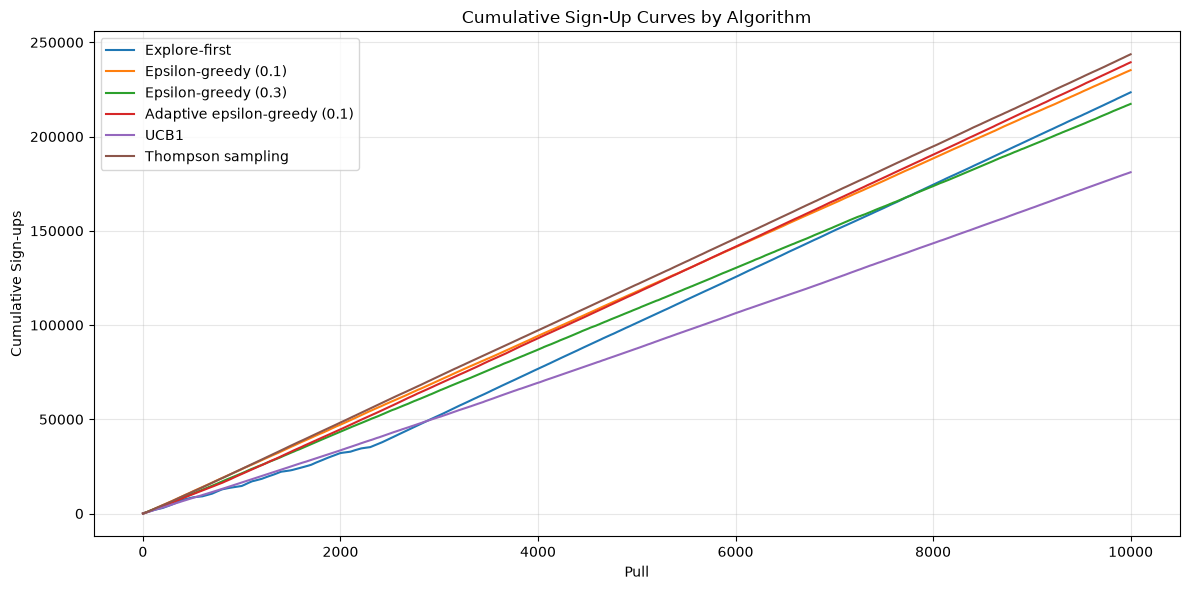

In [22]:
plt.figure(figsize=(12, 6))

for label, rewards in curves.items():
    number_to_plot = min(NUM_PULLS_PER_ALGORITHM, len(rewards))
    pulls = range(1, number_to_plot + 1)

    plt.plot(pulls, rewards[:number_to_plot], label=label)

plt.xlabel("Pull")
plt.ylabel("Cumulative Sign-ups")
plt.title("Cumulative Sign-Up Curves by Algorithm")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join("..", "plots", "signup_curves.png"))
plt.show()

### Use Best Algorithm

In [ ]:
username = input("Group username: ").strip()
password = getpass("Group password: ")

num_pulls_completed = 6 * NUM_PULLS_PER_ALGORITHM

post_experiment_status = status(username, password)
assert MAX_GROUP_PULLS == post_experiment_status["MaxPulls"]
assert num_pulls_completed == post_experiment_status["PullsUsed"]

# Shows progress after all the experiments
print(f"Post experiment status: {post_experiment_status}")

del password

Post experiment status: {'PullsUsed': 5000, 'NetReward': 242815, 'MaxPulls': 1000000, 'Open': True}


In [29]:
# Includes the number of pulls used for experimentation on the best algorithm
total_num_pulls_using_best_alg = MAX_GROUP_PULLS - num_pulls_completed + NUM_PULLS_PER_ALGORITHM
total_num_pulls_using_best_alg

996000

In [ ]:
# username = input("Group username: ").strip()
# password = getpass("Group password: ")
# best_alg_arm_records = conduct_ep_greedy(
#     username,
#     password,
#     ARMS,
#     total_num_pulls_using_best_alg,
#     0.1
# )

# print(f"Average reward per pull for best algorithm: {calculate_average_reward_per_pull(best_alg_arm_records)}")
# print(f"Final status: {status(username, password)}")

# del password

Average reward per pull for best algorithm: 51.844170682730926
Final status: {'PullsUsed': 1000000, 'NetReward': 51828706, 'MaxPulls': 1000000, 'Open': False}


## 4. Prepare the Canvas submission

Submit one PDF report and one HTML code file per group. Do not zip them. The report is limited to four pages, excluding appendices, and its cover page must include group members' names and student numbers and the group username. Python or R may be used. Include the prompts used if you use an LLM such as ChatGPT.

For Python, save the completed notebook and export it to HTML without re-executing live server cells. If Jupyter nbconvert is available, run this command in a terminal from the notebook folder:

```text
jupyter nbconvert --to html "GP3 Starter.ipynb"
```

Do not add `--execute`: exporting should use saved outputs, not make more pulls. Open the exported HTML to check that your code and relevant results are visible and no password appears. Use a clear filename for your completed submission.